In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.pipeline import Pipeline

from sklearn.linear_model import LinearRegression, Ridge, Lasso

from sklearn.metrics import (
    mean_squared_error,
    mean_absolute_error,
    r2_score
)

import warnings
warnings.filterwarnings("ignore")

print("All libraries imported successfully!")

All libraries imported successfully!


In [2]:
housing = fetch_california_housing(as_frame=True)

df = housing.frame.copy()

print("Dataset loaded successfully!")

print("\nFirst five rows:")
display(df.head())

print("\nDataset shape:")
print(df.shape)

print("\nColumn names:")
print(df.columns.tolist())

Dataset loaded successfully!

First five rows:


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422



Dataset shape:
(20640, 9)

Column names:
['MedInc', 'HouseAge', 'AveRooms', 'AveBedrms', 'Population', 'AveOccup', 'Latitude', 'Longitude', 'MedHouseVal']


In [3]:
print("Dataset Information:")
df.info()

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicate Rows:")
print(df.duplicated().sum())

print("\nStatistical Summary:")
display(df.describe())

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 9 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   MedInc       20640 non-null  float64
 1   HouseAge     20640 non-null  float64
 2   AveRooms     20640 non-null  float64
 3   AveBedrms    20640 non-null  float64
 4   Population   20640 non-null  float64
 5   AveOccup     20640 non-null  float64
 6   Latitude     20640 non-null  float64
 7   Longitude    20640 non-null  float64
 8   MedHouseVal  20640 non-null  float64
dtypes: float64(9)
memory usage: 1.4 MB

Missing Values:
MedInc         0
HouseAge       0
AveRooms       0
AveBedrms      0
Population     0
AveOccup       0
Latitude       0
Longitude      0
MedHouseVal    0
dtype: int64

Duplicate Rows:
0

Statistical Summary:


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
count,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000
mean,3.870671,28.639486,5.429000,1.096675,1425.476744,3.070655,35.631861,-119.569704,2.068558
std,1.899822,12.585558,2.474173,0.473911,1132.462122,10.386050,2.135952,2.003532,1.153956
min,0.499900,1.000000,0.846154,0.333333,3.000000,0.692308,32.540000,-124.350000,0.149990
25%,2.563400,18.000000,4.440716,1.006079,787.000000,2.429741,33.930000,-121.800000,1.196000
50%,3.534800,29.000000,5.229129,1.048780,1166.000000,2.818116,34.260000,-118.490000,1.797000
75%,4.743250,37.000000,6.052381,1.099526,1725.000000,3.282261,37.710000,-118.010000,2.647250
max,15.000100,52.000000,141.909091,34.066667,35682.000000,1243.333333,41.950000,-114.310000,5.000010


# EDA

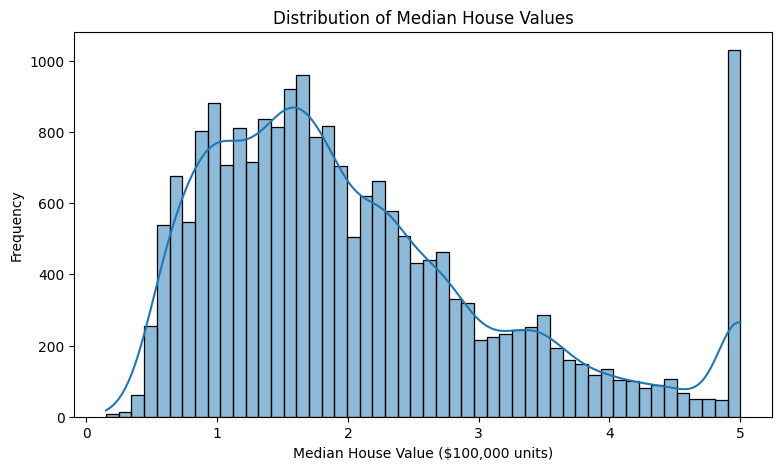

In [4]:
plt.figure(figsize=(9, 5))

sns.histplot(
    df["MedHouseVal"],
    bins=50,
    kde=True
)

plt.title("Distribution of Median House Values")
plt.xlabel("Median House Value ($100,000 units)")
plt.ylabel("Frequency")

plt.show()

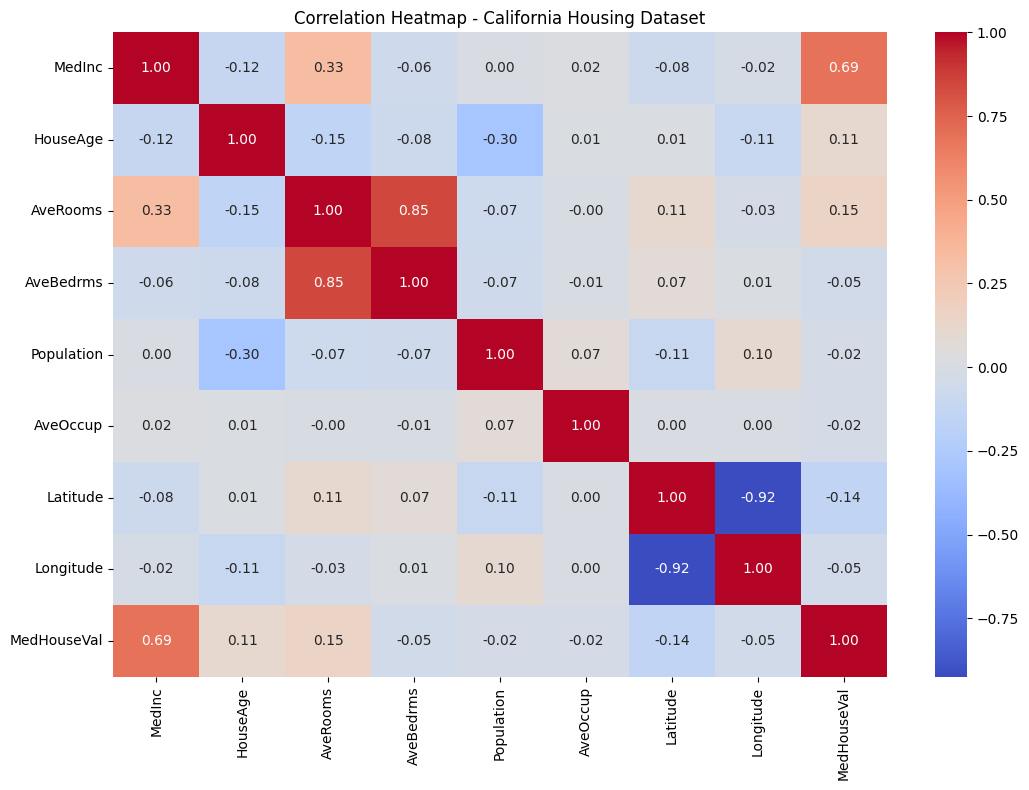

In [5]:
plt.figure(figsize=(11, 8))

sns.heatmap(
    df.corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap - California Housing Dataset")
plt.tight_layout()
plt.show()

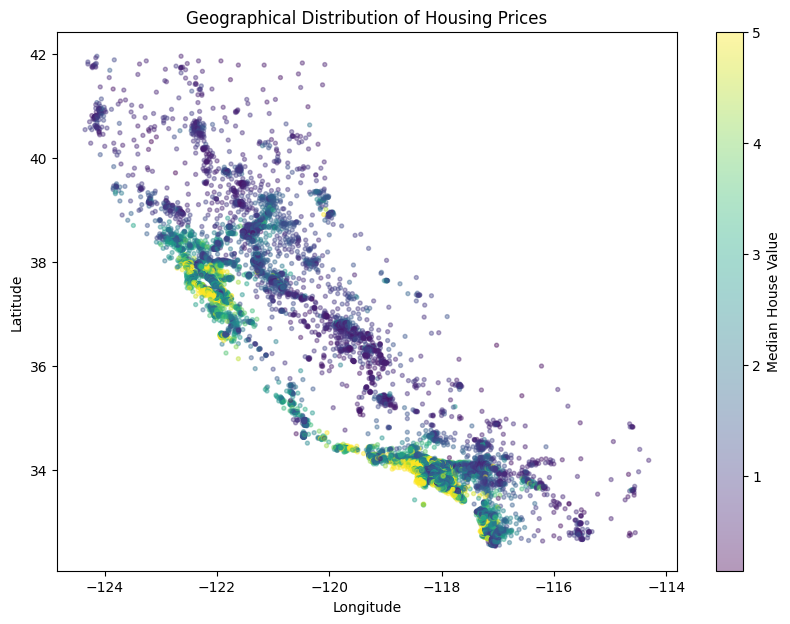

In [6]:
plt.figure(figsize=(10, 7))

scatter = plt.scatter(
    df["Longitude"],
    df["Latitude"],
    c=df["MedHouseVal"],
    cmap="viridis",
    alpha=0.4,
    s=8
)

plt.colorbar(scatter, label="Median House Value")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.title("Geographical Distribution of Housing Prices")

plt.show()

## Seprate Feature and Target 

In [10]:
X = df.drop(columns=["MedHouseVal"])
y = df["MedHouseVal"]

print("Features shape:", X.shape)
print("Target shape:", y.shape)

print("\nInput features:")
print(X.columns.tolist())

Features shape: (20640, 8)
Target shape: (20640,)

Input features:
['MedInc', 'HouseAge', 'AveRooms', 'AveBedrms', 'Population', 'AveOccup', 'Latitude', 'Longitude']


In [11]:
X_train, X_test, y_train, y_test = train_test_split(X, y , test_size=0.2 , random_state=43)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

Training samples: 16512
Testing samples: 4128


## Build the preprocessing and feature engineering pipeline

In [12]:
preprocessor = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),

    ("interaction", PolynomialFeatures(
        degree=2,
        interaction_only=True,
        include_bias=False
    )),

    ("scaler", StandardScaler())
])

X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

print("Original number of features:", X_train.shape[1])
print("Features after engineering:", X_train_processed.shape[1])

print("Training data processed successfully!")

Original number of features: 8
Features after engineering: 36
Training data processed successfully!


## Train Ordinary Least Squares (OLS)

In [13]:
ols_model = LinearRegression()

ols_model.fit(
    X_train_processed,
    y_train
)

ols_predictions = ols_model.predict(X_test_processed)

print("OLS model trained successfully!")

OLS model trained successfully!


## Train Ridge Regression using GridSearchCV

In [14]:
ridge_pipeline = Pipeline([
    ("regressor", Ridge())
])

ridge_params = {
    "regressor__alpha": [0.01, 0.1, 1, 10, 100, 1000]
}

ridge_grid = GridSearchCV(
    ridge_pipeline,
    ridge_params,
    cv=5,
    scoring="neg_root_mean_squared_error",
    n_jobs=-1
)

ridge_grid.fit(X_train_processed, y_train)

ridge_model = ridge_grid.best_estimator_

ridge_predictions = ridge_model.predict(X_test_processed)

print("Best Ridge alpha:", ridge_grid.best_params_)
print("Ridge model trained successfully!")

Best Ridge alpha: {'regressor__alpha': 1000}
Ridge model trained successfully!


## Train Lasso Regression using GridSearchCV

In [15]:
lasso_pipeline = Pipeline([
    ("regressor", Lasso(max_iter=20000))
])

lasso_params = {
    "regressor__alpha": [0.0001, 0.001, 0.01, 0.1, 1, 10]
}

lasso_grid = GridSearchCV(
    lasso_pipeline,
    lasso_params,
    cv=5,
    scoring="neg_root_mean_squared_error",
    n_jobs=-1
)

lasso_grid.fit(X_train_processed, y_train)

lasso_model = lasso_grid.best_estimator_

lasso_predictions = lasso_model.predict(X_test_processed)

print("Best Lasso alpha:", lasso_grid.best_params_)
print("Lasso model trained successfully!")

Best Lasso alpha: {'regressor__alpha': 0.01}
Lasso model trained successfully!


## Calculate RMSE, MAE and R²

In [16]:
models_predictions = {
    "OLS Regression": ols_predictions,
    "Ridge Regression": ridge_predictions,
    "Lasso Regression": lasso_predictions
}

results = []

for name, predictions in models_predictions.items():

    rmse = np.sqrt(mean_squared_error(y_test, predictions))
    mae = mean_absolute_error(y_test, predictions)
    r2 = r2_score(y_test, predictions)

    results.append({
        "Model": name,
        "RMSE": rmse,
        "MAE": mae,
        "R2 Score": r2
    })

results_df = pd.DataFrame(results).set_index("Model")

print("REGRESSION MODEL COMPARISON")
display(results_df.round(4))

REGRESSION MODEL COMPARISON


,RMSE,MAE,R2 Score
Model,,,
OLS Regression,0.9437,0.4920,0.3322
Ridge Regression,0.7197,0.5291,0.6116
Lasso Regression,0.7168,0.5277,0.6147


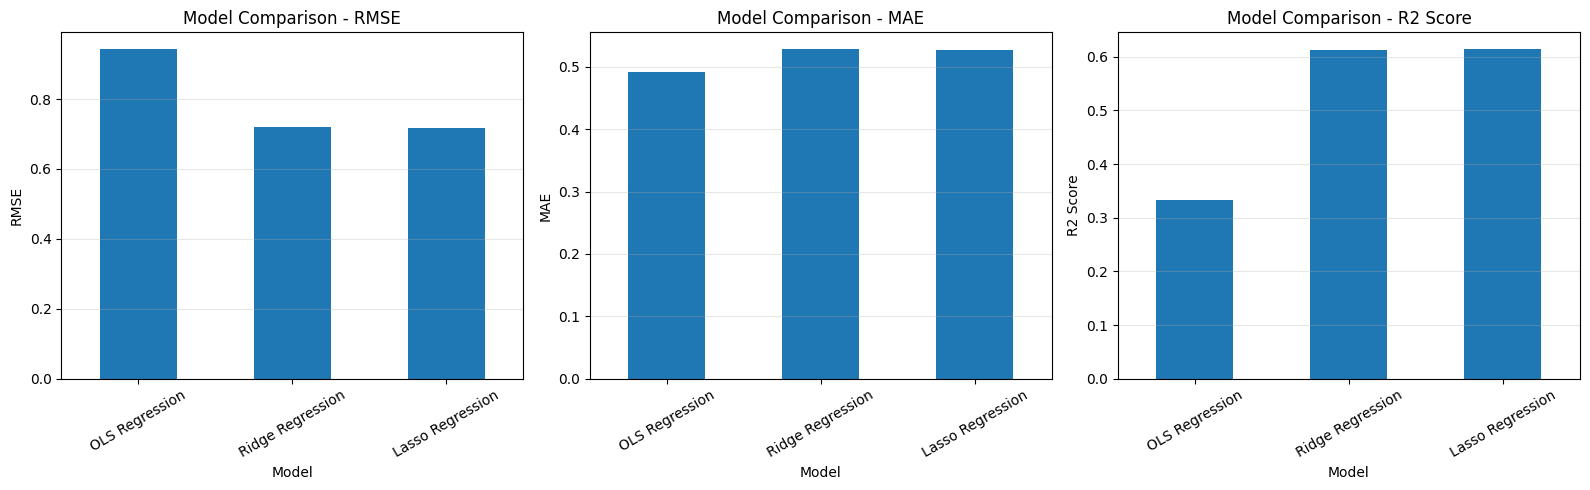

In [17]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

metrics = ["RMSE", "MAE", "R2 Score"]

for ax, metric in zip(axes, metrics):

    results_df[metric].plot(
        kind="bar",
        ax=ax,
        rot=30
    )

    ax.set_title(f"Model Comparison - {metric}")
    ax.set_ylabel(metric)
    ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

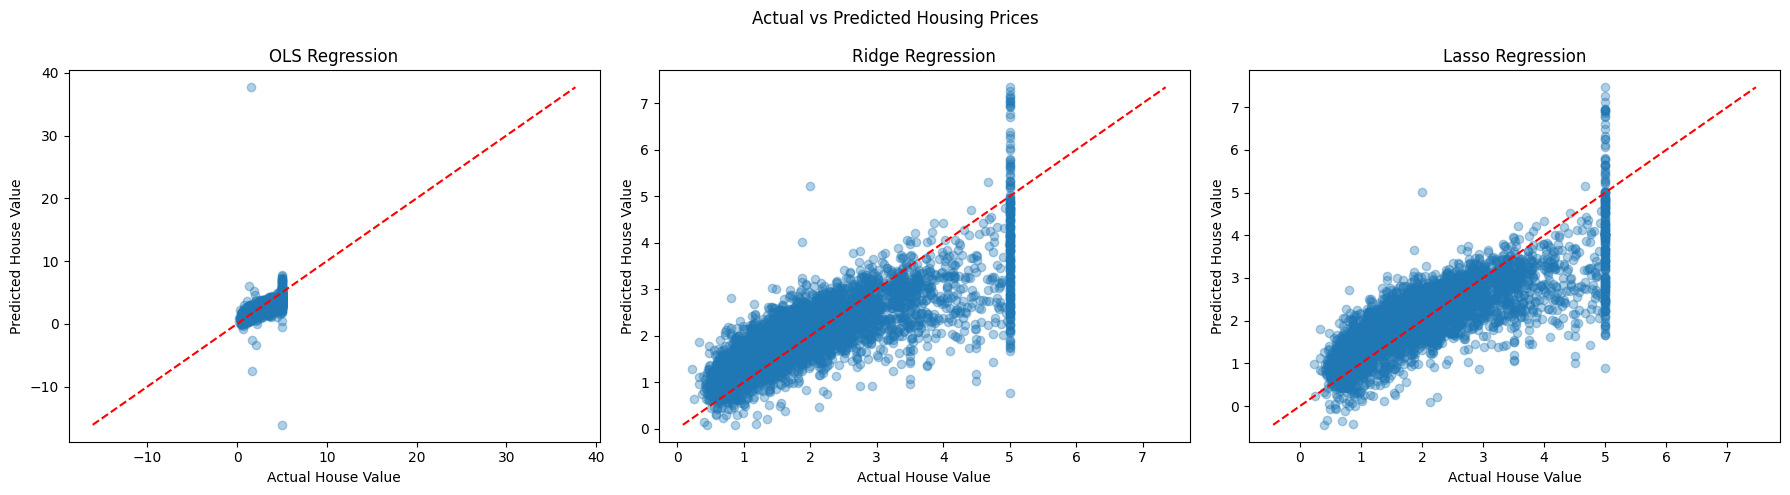

In [19]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, (name, predictions) in zip(
    axes, models_predictions.items()
):

    ax.scatter(
        y_test,
        predictions,
        alpha=0.35
    )

    min_val = min(y_test.min(), predictions.min())
    max_val = max(y_test.max(), predictions.max())

    ax.plot(
        [min_val, max_val],
        [min_val, max_val],
        "r--"
    )

    ax.set_title(name)
    ax.set_xlabel("Actual House Value")
    ax.set_ylabel("Predicted House Value")

plt.suptitle("Actual vs Predicted Housing Prices")
plt.tight_layout()
plt.show()

## Residual = Actual - Predicted

In [20]:
residuals = {}

for name, predictions in models_predictions.items():

    residuals[name] = y_test - predictions

print("Residuals calculated successfully!")

Residuals calculated successfully!


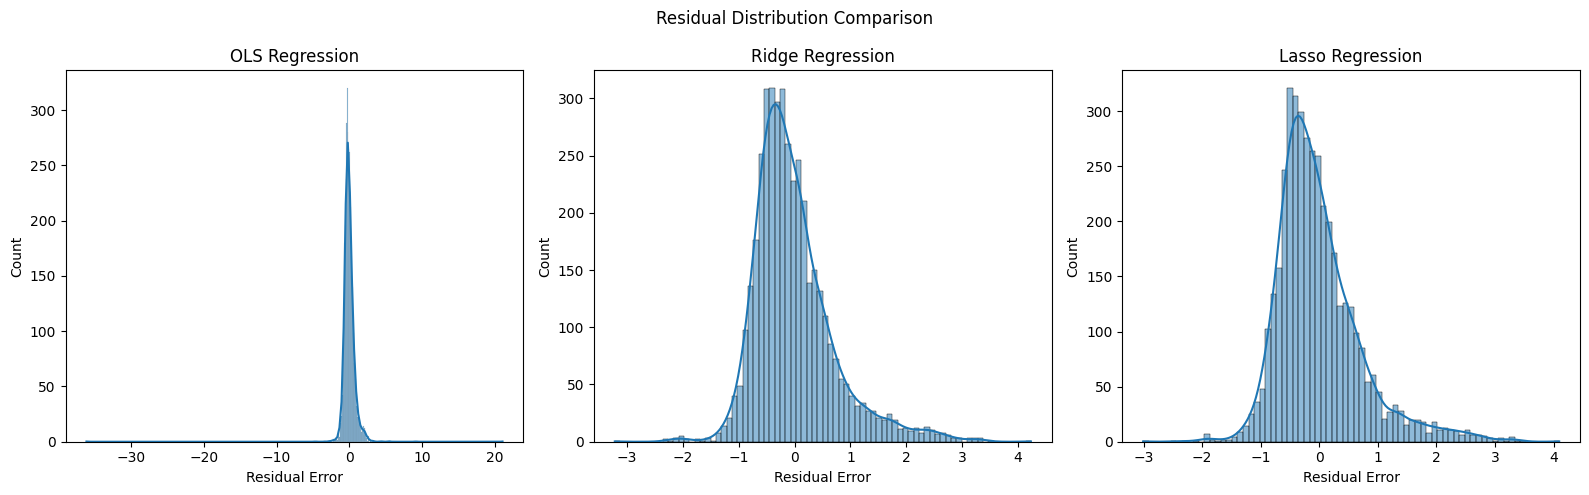

In [21]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

for ax, (name, residual) in zip(
    axes, residuals.items()
):

    sns.histplot(
        residual,
        kde=True,
        ax=ax
    )

    ax.set_title(name)
    ax.set_xlabel("Residual Error")

plt.suptitle("Residual Distribution Comparison")
plt.tight_layout()
plt.show()

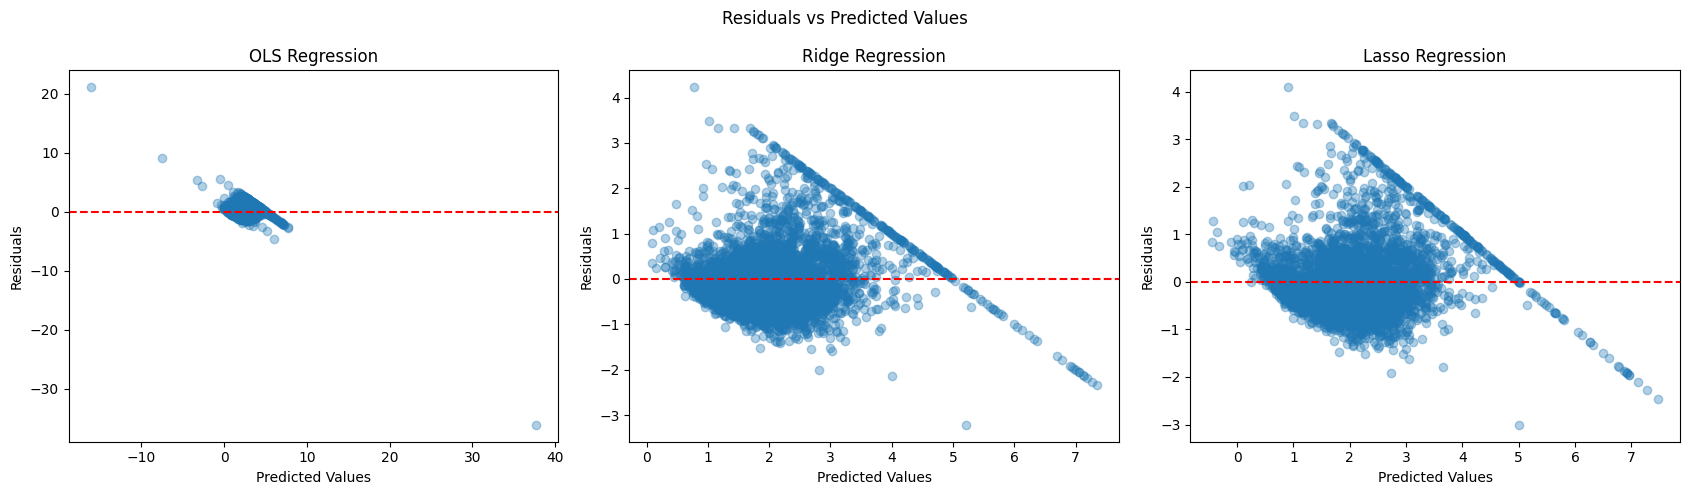

In [22]:
fig, axes = plt.subplots(1, 3, figsize=(17, 5))

for ax, (name, predictions) in zip(
    axes, models_predictions.items()
):

    ax.scatter(
        predictions,
        residuals[name],
        alpha=0.35
    )

    ax.axhline(
        y=0,
        color="red",
        linestyle="--"
    )

    ax.set_title(name)
    ax.set_xlabel("Predicted Values")
    ax.set_ylabel("Residuals")

plt.suptitle("Residuals vs Predicted Values")
plt.tight_layout()
plt.show()

## Identify best model 

In [23]:
best_model_name = results_df["RMSE"].idxmin()

print("Best Performing Model:", best_model_name)

print("\nPerformance:")
display(
    results_df.loc[[best_model_name]].round(4)
)

Best Performing Model: Lasso Regression

Performance:


,RMSE,MAE,R2 Score
Model,,,
Lasso Regression,0.7168,0.5277,0.6147


In [24]:
ridge_coefficients = ridge_model.named_steps["regressor"].coef_

lasso_coefficients = lasso_model.named_steps["regressor"].coef_

coefficient_comparison = pd.DataFrame({
    "Ridge": ridge_coefficients,
    "Lasso": lasso_coefficients
})

print("Regularized Model Coefficients:")
display(coefficient_comparison.head(15))

Regularized Model Coefficients:


,Ridge,Lasso
0,0.221257,0.000000
1,0.026064,0.000000
2,-0.038494,-0.000000
3,0.067313,0.000000
4,-0.039556,-0.000000
5,-0.055515,-0.037089
6,-0.363788,-0.823366
7,-0.489965,-0.758723
8,0.169628,0.211750
9,-0.047505,-0.000000


### In this project, a real estate housing price prediction system was developed using the California Housing dataset. Three regression algorithms, namely Ordinary Least Squares, Ridge Regression, and Lasso Regression, were implemented and compared.

### Data preprocessing included missing value imputation, feature engineering through interaction terms, and feature standardization. Ridge and Lasso regression models were optimized using GridSearchCV with five-fold cross-validation.

### Model performance was evaluated using RMSE, MAE, and R² score. Actual versus predicted plots and residual analysis were also performed to understand prediction errors and model behavior.

### The best-performing regression model was (Lasso Regression) selected based on its RMSE score. 